# Lohnt sich das? – Der Kontroll-Rechner
**Team 5 (Roland, Leo, Tobias)** · Bonus

Unser Modell sagt, **wer** verdächtig ist. Aber **wie viele** Kunden soll STEG kontrollieren? Jede Kontrolle kostet Geld, und nicht jede findet einen Betrüger.

**So benutzt ihr den Rechner:** In Abschnitt 2 die zwei Zahlen ändern, dann *Run All*.

| # | Schritt |
|---|---|
| 1 | Setup |
| 2 | Eingaben |
| 3 | Vorhersagen für jeden Kunden |
| 4 | Der Rechner |
| 5 | Ergebnis |
| 6 | Gewinnkurve |
| 7 | Warum genau dort aufhören? |
| 8 | Vergleich mit anderen Strategien |
| 9 | Was wäre wenn? (Szenarien) |
| 10 | Fazit |

**Voraussetzung:** `04` bis `07` wurden einmal ausgeführt (`data/fd_features.csv` und `models/fd_best_model.joblib` existieren).

## 1 · Setup

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from fd_utils import cv

sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
MODEL_DIR = Path("models")

## 2 · Eingaben
**Hier dürft ihr spielen.** Die Standardwerte sind unsere Schätzung:

* **Kosten pro Kontrolle: 25 €** – eine Studie aus Europa kommt auf ca. 22,55 € pro Vor-Ort-Kontrolle (Personal, Anfahrt, Ausrüstung). In Tunesien sind die Löhne niedriger, dafür muss bei einem Fund noch ein Gerichtsvollzieher kommen.
* **Wert eines gefundenen Betrugs: 150 €** – ca. 100 € Nachzahlung (etwa die Hälfte von 110 kWh pro Monat, 2 Jahre lang, zum tunesischen Strompreis) plus ca. 50 €, weil der Betrug danach aufhört.

Das sind **Annahmen**, keine echten STEG-Zahlen.

In [2]:
KOSTEN_PRO_KONTROLLE = 25   # Euro
WERT_PRO_BETRUG = 150       # Euro

# Optional: Wie viele Kontrollen schaffen die Kontrolleure höchstens? None = keine Grenze
MAX_KONTROLLEN = None

## 3 · Vorhersagen für jeden Kunden
Wir brauchen für jeden Kunden eine Betrugs-Wahrscheinlichkeit von einem Modell, das ihn **nicht** im Training gesehen hat. Dafür nehmen wir wie in `08_fehleranalyse.ipynb` `cross_val_predict` auf dem Train-Teil (108.394 Kunden). Das dauert etwa eine halbe Minute.

In [3]:
df = pd.read_csv(DATA_DIR / "fd_features.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")
df = df.merge(df_split, on="client_id", how="left")
df_train = df[df["split"] == "train"]

X_train = df_train.drop(columns=["client_id", "creation_date", "split", "target"])
y_train = df_train["target"]

model = joblib.load(MODEL_DIR / "fd_best_model.joblib")
proba = cross_val_predict(clone(model), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

# Kunden nach Wahrscheinlichkeit sortieren: die verdächtigsten zuerst
df_liste = pd.DataFrame({"target": y_train.values, "proba": proba})
df_liste = df_liste.sort_values("proba", ascending=False).reset_index(drop=True)
df_liste.head()

,target,proba
0,1,0.975196
1,1,0.974033
2,1,0.973566
3,1,0.973281
4,1,0.971317


## 4 · Der Rechner
Wir gehen die Liste von oben nach unten durch und rechnen nach **jeder** Kontrolle:

* **Kosten** = Anzahl Kontrollen × Kosten pro Kontrolle
* **Ertrag** = gefundene Betrüger × Wert pro Betrug
* **Gewinn** = Ertrag − Kosten

Das Optimum ist die Stelle mit dem höchsten Gewinn.

In [4]:
def kontroll_rechner(df_liste, kosten, wert, max_kontrollen=None):
    tabelle = df_liste.copy()
    tabelle["kontrollen"] = np.arange(1, len(tabelle) + 1)
    tabelle["anteil_kontrolliert"] = tabelle["kontrollen"] / len(tabelle)
    tabelle["gefunden"] = tabelle["target"].cumsum()
    tabelle["kosten"] = tabelle["kontrollen"] * kosten
    tabelle["ertrag"] = tabelle["gefunden"] * wert
    tabelle["gewinn"] = tabelle["ertrag"] - tabelle["kosten"]

    # Kapazitätsgrenze der Kontrolleure
    if max_kontrollen is not None:
        tabelle = tabelle.head(max_kontrollen)

    optimum = tabelle.loc[tabelle["gewinn"].idxmax()]
    return tabelle, optimum


tabelle, optimum = kontroll_rechner(df_liste, KOSTEN_PRO_KONTROLLE, WERT_PRO_BETRUG, MAX_KONTROLLEN)

## 5 · Ergebnis

In [5]:
alle_betrueger = df_liste["target"].sum()
break_even = KOSTEN_PRO_KONTROLLE / WERT_PRO_BETRUG

print(f"Eingaben: {KOSTEN_PRO_KONTROLLE} € pro Kontrolle, {WERT_PRO_BETRUG} € pro gefundenem Betrug")
print(f"Eine Kontrolle lohnt sich ab einer Trefferquote von {break_even:.1%}")
print()
if optimum["gewinn"] <= 0:
    print("Ergebnis: Keine Kontrolle lohnt sich. Lieber gar nicht kontrollieren.")
else:
    print(f"Optimal: die verdächtigsten {optimum['anteil_kontrolliert']:.1%} der Kunden kontrollieren")
    print(f"  Kontrollen:          {optimum['kontrollen']:,.0f}")
    print(f"  gefundene Betrüger:  {optimum['gefunden']:,.0f} ({optimum['gefunden'] / alle_betrueger:.1%} aller Betrüger)")
    print(f"  Trefferquote:        {optimum['gefunden'] / optimum['kontrollen']:.1%}")
    print(f"  Kosten:              {optimum['kosten']:,.0f} €")
    print(f"  Ertrag:              {optimum['ertrag']:,.0f} €")
    print(f"  Gewinn:              {optimum['gewinn']:,.0f} €  ({optimum['gewinn'] / optimum['kontrollen']:.2f} € pro Kontrolle)")

Eingaben: 25 € pro Kontrolle, 150 € pro gefundenem Betrug
Eine Kontrolle lohnt sich ab einer Trefferquote von 16.7%

Optimal: die verdächtigsten 8.2% der Kunden kontrollieren
  Kontrollen:          8,920
  gefundene Betrüger:  2,682 (44.3% aller Betrüger)
  Trefferquote:        30.1%
  Kosten:              223,000 €
  Ertrag:              402,300 €
  Gewinn:              179,300 €  (20.10 € pro Kontrolle)


**Was fällt auf?** (mit den Standardwerten 25 € / 150 €)
* Eine Kontrolle lohnt sich ab einer Trefferquote von 16,7 % (25 ÷ 150).
* Optimal ist es, die **verdächtigsten 8,2 %** zu kontrollieren (8.920 Kunden). Fast jede dritte Kontrolle ist ein Treffer, und man findet 44 % aller Betrüger.
* Gewinn: rund **179.000 €**, also gut 20 € pro Kontrolle.
* Die Zahlen gelten für die 108.394 Kunden im Train-Teil. Für alle Kunden von STEG wäre der Gewinn entsprechend größer.

## 6 · Gewinnkurve
Wie entwickelt sich der Gewinn, wenn man immer mehr Kunden kontrolliert? Zum Vergleich: zufällig kontrollieren (ohne Modell).

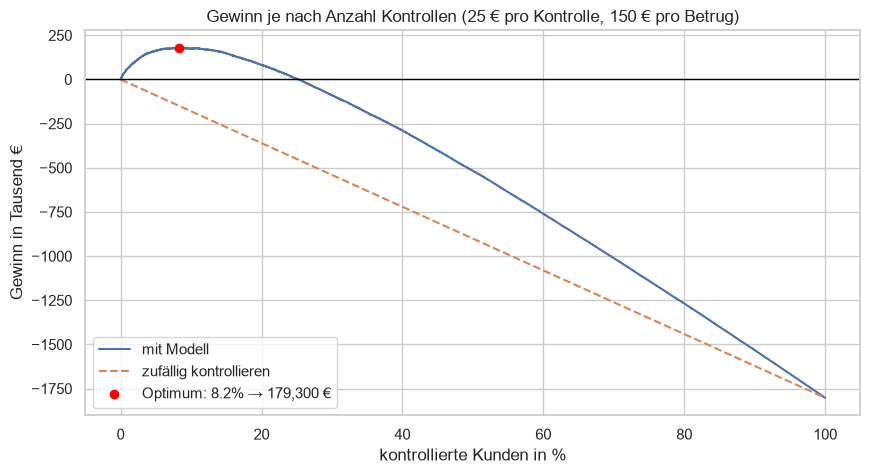

In [6]:
quote_gesamt = df_liste["target"].mean()
gewinn_zufall = tabelle["kontrollen"] * (quote_gesamt * WERT_PRO_BETRUG - KOSTEN_PRO_KONTROLLE)

plt.figure(figsize=(10, 5))
plt.plot(tabelle["anteil_kontrolliert"] * 100, tabelle["gewinn"] / 1000, label="mit Modell")
plt.plot(tabelle["anteil_kontrolliert"] * 100, gewinn_zufall / 1000, linestyle="--", label="zufällig kontrollieren")
plt.axhline(0, color="black", linewidth=1)
plt.scatter(optimum["anteil_kontrolliert"] * 100, optimum["gewinn"] / 1000, color="red", zorder=3,
            label=f"Optimum: {optimum['anteil_kontrolliert']:.1%} → {optimum['gewinn']:,.0f} €")
plt.title(f"Gewinn je nach Anzahl Kontrollen ({KOSTEN_PRO_KONTROLLE} € pro Kontrolle, {WERT_PRO_BETRUG} € pro Betrug)")
plt.xlabel("kontrollierte Kunden in %")
plt.ylabel("Gewinn in Tausend €")
plt.legend()
plt.show()

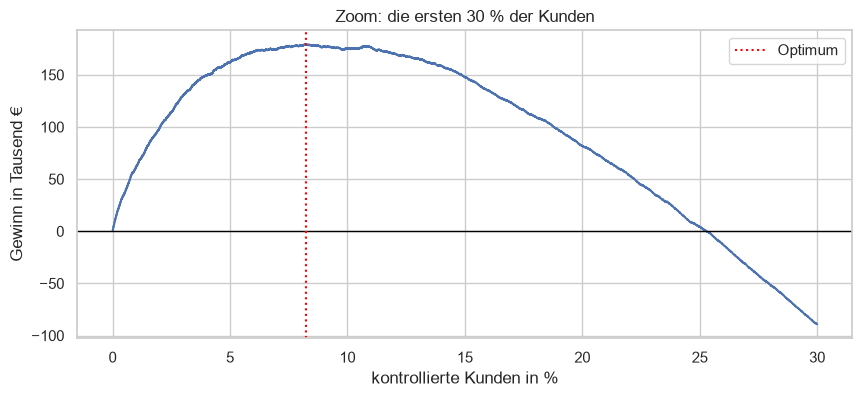

In [7]:
# Zoom auf den interessanten Bereich (erste 30 %)
bereich = tabelle[tabelle["anteil_kontrolliert"] <= 0.3]

plt.figure(figsize=(10, 4))
plt.plot(bereich["anteil_kontrolliert"] * 100, bereich["gewinn"] / 1000)
plt.axhline(0, color="black", linewidth=1)
plt.axvline(optimum["anteil_kontrolliert"] * 100, color="red", linestyle=":", label="Optimum")
plt.title("Zoom: die ersten 30 % der Kunden")
plt.xlabel("kontrollierte Kunden in %")
plt.ylabel("Gewinn in Tausend €")
plt.legend()
plt.show()

**Was fällt auf?**
* Am Anfang steigt der Gewinn steil, weil oben auf der Liste die meisten Betrüger stehen.
* Nach dem Optimum fällt er wieder: Ab da kostet jede Kontrolle mehr, als sie einbringt. Wer alle kontrolliert, macht sogar Verlust.
* **Zufällig kontrollieren** lohnt sich mit diesen Werten nie: Bei 5,6 % Treffern bringt eine Kontrolle im Schnitt 8,40 € und kostet 25 €.
* Die Kurve ist um das Optimum herum ziemlich flach. Ob man 7 % oder 10 % kontrolliert, macht kaum einen Unterschied.

## 7 · Warum genau dort aufhören?
Ganz oben auf der Liste ist fast jeder zweite Kunde ein Betrüger. Je weiter unten, desto seltener. Wir zeigen die Trefferquote der **jeweils nächsten 1.000 Kontrollen**.

Solange diese Trefferquote über der **Break-even-Linie** (Kosten ÷ Wert) liegt, bringt jede weitere Kontrolle mehr ein, als sie kostet. Fällt sie darunter, macht jede weitere Kontrolle Verlust.

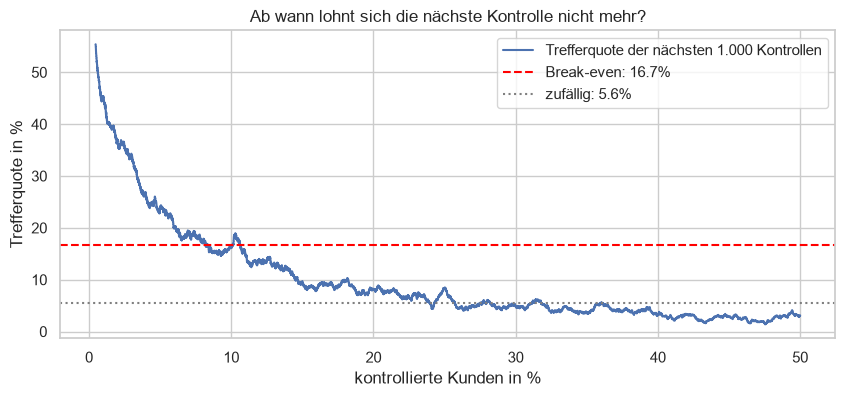

In [8]:
# Trefferquote in einem "gleitenden Fenster" von 1.000 Kontrollen
tabelle["trefferquote_naechste"] = tabelle["target"].rolling(1000, center=True).mean()
bereich = tabelle[tabelle["anteil_kontrolliert"] <= 0.5]

plt.figure(figsize=(10, 4))
plt.plot(bereich["anteil_kontrolliert"] * 100, bereich["trefferquote_naechste"] * 100, label="Trefferquote der nächsten 1.000 Kontrollen")
plt.axhline(break_even * 100, color="red", linestyle="--", label=f"Break-even: {break_even:.1%}")
plt.axhline(quote_gesamt * 100, color="grey", linestyle=":", label=f"zufällig: {quote_gesamt:.1%}")
plt.title("Ab wann lohnt sich die nächste Kontrolle nicht mehr?")
plt.xlabel("kontrollierte Kunden in %")
plt.ylabel("Trefferquote in %")
plt.legend()
plt.show()

Das Optimum liegt genau dort, wo die blaue Linie die rote Linie schneidet.

## 8 · Vergleich mit anderen Strategien

In [9]:
def zeile(name, anzahl):
    # Ergebnis, wenn man die verdächtigsten "anzahl" Kunden kontrolliert
    t = tabelle.iloc[int(anzahl) - 1]
    return {"Strategie": name, "Kontrollen": int(t["kontrollen"]), "gefundene Betrüger": int(t["gefunden"]),
            "Trefferquote": round(t["gefunden"] / t["kontrollen"], 3), "Gewinn (€)": round(t["gewinn"])}


n = len(tabelle)
strategien = pd.DataFrame([
    zeile("Optimum laut Rechner", optimum["kontrollen"]),
    zeile("Top 5 %", n * 0.05),
    zeile("Top 10 %", n * 0.10),
    zeile("Top 20 %", n * 0.20),
    zeile("alle kontrollieren", n),
])

# Zufällig gleich viele wie im Optimum kontrollieren
k = optimum["kontrollen"]
strategien.loc[len(strategien)] = {
    "Strategie": "zufällig (gleich viele wie Optimum)", "Kontrollen": int(k),
    "gefundene Betrüger": round(k * quote_gesamt), "Trefferquote": round(quote_gesamt, 3),
    "Gewinn (€)": round(k * (quote_gesamt * WERT_PRO_BETRUG - KOSTEN_PRO_KONTROLLE)),
}

strategien

,Strategie,Kontrollen,gefundene Betrüger,Trefferquote,Gewinn (€)
0,Optimum laut Rechner,8920,2682,0.301,179300
1,Top 5 %,5419,1984,0.366,162125
2,Top 10 %,10839,2976,0.275,175425
3,Top 20 %,21678,4159,0.192,81900
4,alle kontrollieren,108394,6053,0.056,-1801900
5,zufällig (gleich viele wie Optimum),8920,498,0.056,-148283


**Was fällt auf?**
* "Top 10 %" (unsere Schwelle aus `08_fehleranalyse.ipynb`) ist fast so gut wie das genaue Optimum (175.000 € statt 179.000 €). Eine einfache Faustregel reicht also.
* **Mit Modell** +179.000 €, **zufällig** gleich viele Kontrollen: −148.000 €. Das Modell macht aus einem Verlustgeschäft ein Gewinngeschäft.
* Alle zu kontrollieren kostet 1,8 Mio. € Verlust.

## 9 · Was wäre wenn? (Szenarien)
Die Kosten und der Wert sind geschätzt. Wie ändert sich die Empfehlung, wenn sie anders sind? Jedes Feld zeigt den **optimalen Anteil der Kunden**, den man kontrollieren sollte.

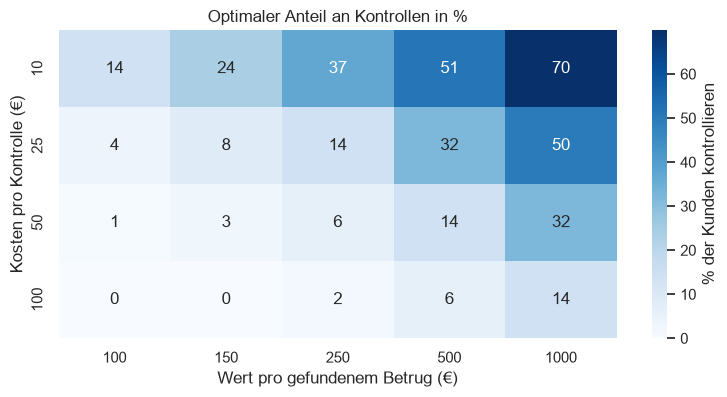

,100,150,250,500,1000
10,14.4,23.7,36.9,51.3,69.9
25,3.8,8.2,14.4,31.9,49.9
50,0.8,2.9,6.2,14.4,31.9
100,0.0,0.2,1.6,6.2,14.4


In [10]:
kosten_liste = [10, 25, 50, 100]
wert_liste = [100, 150, 250, 500, 1000]

szenarien = pd.DataFrame(index=kosten_liste, columns=wert_liste, dtype=float)
for kosten in kosten_liste:
    for wert in wert_liste:
        _, opt = kontroll_rechner(df_liste, kosten, wert)
        szenarien.loc[kosten, wert] = opt["anteil_kontrolliert"] * 100 if opt["gewinn"] > 0 else 0

plt.figure(figsize=(9, 4))
sns.heatmap(szenarien, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% der Kunden kontrollieren"})
plt.title("Optimaler Anteil an Kontrollen in %")
plt.xlabel("Wert pro gefundenem Betrug (€)")
plt.ylabel("Kosten pro Kontrolle (€)")
plt.show()

szenarien.round(1)

**Was fällt auf?**
* Entscheidend ist nur das **Verhältnis** von Wert zu Kosten. Überall, wo der Wert 10-mal so hoch ist wie die Kosten (z. B. 10 € / 100 €, 50 € / 500 €), kommt dasselbe heraus: etwa 14 %.
* Ist eine Kontrolle teuer und der Betrug klein (100 € / 100 €), lohnt sich gar nichts.
* Ist eine Kontrolle billig und der Betrug groß (10 € / 1.000 €), lohnt es sich, gut zwei Drittel der Kunden zu kontrollieren.

## 10 · Fazit
* Mit unseren Schätzungen (25 € pro Kontrolle, 150 € pro Betrug) sollte STEG **die verdächtigsten etwa 8–10 % der Kunden** kontrollieren.
* Damit findet sie fast **die Hälfte aller Betrüger**, und fast jede dritte Kontrolle ist ein Treffer (ohne Modell jede achtzehnte).
* Ohne Modell würden sich Kontrollen bei diesen Werten gar nicht lohnen.

**Grenzen:**
* Kosten und Wert sind **geschätzt**. STEG kann in Abschnitt 2 die eigenen Zahlen eintragen.
* Abschreckung ist nicht eingerechnet: Wenn sich Kontrollen herumsprechen, betrügen vielleicht weniger. Dann lohnt sich Kontrollieren eher noch mehr.
* Ein Teil der "falschen Alarme" sind vielleicht Betrüger, die bisher nur nie erwischt wurden. Die Rechnung ist also eher vorsichtig.